# Academic Performance Prediction Using Supervised Learning
## Notebook 1 of 4 — Data Preprocessing & Exploratory Data Analysis

**Capstone project · Batch AIML 13 · Department of AI & Data Science · GITAM School of CSE, Bengaluru**

**Dataset:** *Student Habits and Academic Performance Dataset* (Kaggle: `aryan208/student-habits-and-academic-performance-dataset`)
— 80,000 student records × 31 attributes covering academic, behavioural, lifestyle and psychological factors.

**What this notebook does**

1. Loads the raw CSV from `data/raw/`
2. Audits the schema, missing values and duplicates
3. Removes outliers with the 1.5 × IQR rule
4. Explores the targets, correlations and habit distributions (figures saved to `reports/figures/`)
5. Writes the cleaned data to `data/processed/cleaned.csv`, used by notebooks 2 and 3

> **VS Code:** open the notebook, choose the project `.venv` as the kernel (top-right **Select Kernel**), then **Run All**.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import FIGURES_DIR, OUTLIER_COLUMNS, RAW_DIR

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 60)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
Path("data/processed").mkdir(parents=True, exist_ok=True)
print("raw data folder:", RAW_DIR)

raw data folder: D:\Downloads\freebuff\data\raw


### 1. Load the dataset

In [2]:
csv_files = sorted(RAW_DIR.glob("*.csv"))
assert csv_files, f"No CSV found in {RAW_DIR} - place the Kaggle dataset there first."

csv_path = csv_files[0]
df = pd.read_csv(csv_path)
print(f"file  : {csv_path.name}")
print(f"shape : {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

file  : student_habits.csv
shape : 80,000 rows x 31 columns


,student_id,age,gender,major,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,previous_gpa,semester,stress_level,dropout_risk,social_activity,screen_time,study_environment,access_to_tutoring,family_income_range,parental_support_level,motivation_level,exam_anxiety_score,learning_style,time_management_score,exam_score
0,100000,26,Male,Computer Science,7.645367,3.0,0.1,Yes,70.3,6.2,Poor,3,Some College,High,6.0,Yes,4.00,5,5.8,No,0,10.9,Co-Learning Group,Yes,High,9,7,8,Reading,3.0,100
1,100001,28,Male,Arts,5.700000,0.5,0.4,No,88.4,7.2,Good,4,PhD,Low,6.8,No,4.00,7,5.8,No,5,8.3,Co-Learning Group,Yes,Low,7,2,10,Reading,6.0,99
2,100002,17,Male,Arts,2.400000,4.2,0.7,No,82.1,9.2,Good,4,High School,Low,5.7,Yes,3.79,4,8.0,No,5,8.0,Library,Yes,High,3,9,6,Kinesthetic,7.6,98
3,100003,27,Other,Psychology,3.400000,4.6,2.3,Yes,79.3,4.2,Fair,3,Master,Medium,8.5,Yes,4.00,6,4.6,No,3,11.7,Co-Learning Group,Yes,Low,5,3,10,Reading,3.2,100
4,100004,25,Female,Business,4.700000,0.8,2.7,Yes,62.9,6.5,Good,6,PhD,Low,9.2,No,4.00,4,5.7,No,2,9.4,Quiet Room,Yes,Medium,9,1,10,Reading,7.1,98


In [3]:
print(df.dtypes.to_string())
print()
df.describe().T.round(2)

student_id                         int64
age                                int64
gender                               str
major                                str
study_hours_per_day              float64
social_media_hours               float64
netflix_hours                    float64
part_time_job                        str
attendance_percentage            float64
sleep_hours                      float64
diet_quality                         str
exercise_frequency                 int64
parental_education_level             str
internet_quality                     str
mental_health_rating             float64
extracurricular_participation        str
previous_gpa                     float64
semester                           int64
stress_level                     float64
dropout_risk                         str
social_activity                    int64
screen_time                      float64
study_environment                    str
access_to_tutoring                   str
family_income_ra

,count,mean,std,min,25%,50%,75%,max
student_id,80000.0,139999.50,23094.16,100000.00,119999.75,139999.50,159999.25,179999.0
age,80000.0,22.00,3.75,16.00,19.00,22.00,25.00,28.0
study_hours_per_day,80000.0,4.17,2.00,0.00,2.80,4.13,5.50,12.0
social_media_hours,80000.0,2.50,1.45,0.00,1.20,2.50,3.80,5.0
netflix_hours,80000.0,2.00,1.16,0.00,1.00,2.00,3.00,4.0
attendance_percentage,80000.0,69.97,17.33,40.00,55.00,69.90,84.90,100.0
sleep_hours,80000.0,7.02,1.47,4.00,6.00,7.00,8.00,12.0
exercise_frequency,80000.0,3.52,2.29,0.00,2.00,4.00,6.00,7.0
mental_health_rating,80000.0,6.80,1.92,1.00,5.50,6.90,8.20,10.0
previous_gpa,80000.0,3.60,0.46,1.64,3.27,3.79,4.00,4.0


### 2. Data audit - missing values, duplicates, class balance
The capstone methodology requires handling missing values, duplicates and outliers before modelling. Missing values (if any) are later imputed **inside** the model pipeline (median for numeric, most frequent for categorical), so live inputs can also be blank.

In [4]:
missing = df.isna().sum()
missing = missing[missing > 0]
print("missing values per column:")
print(missing.to_string() if len(missing) else "  none")
print(f"\nduplicate rows: {df.duplicated().sum()}")
print("\ntarget class balance (dropout_risk):")
print(df["dropout_risk"].value_counts(normalize=True).rename_axis("class").to_string())
print(f"\nexam_score: mean={df['exam_score'].mean():.1f}  "
      f"min={df['exam_score'].min():.0f}  max={df['exam_score'].max():.0f}")

missing values per column:
  none



duplicate rows: 0

target class balance (dropout_risk):
class
No     0.980225
Yes    0.019775

exam_score: mean=89.1  min=36  max=100


### 3. Outlier removal (1.5 × IQR fences)

Rows outside `[Q1 - 1.5·IQR, Q3 + 1.5·IQR]` on the core numeric columns are dropped. Column choice comes from `src/config.py` (`OUTLIER_COLUMNS`).

In [5]:
def remove_outliers(frame, columns):
    mask = pd.Series(True, index=frame.index)
    removed = {}
    for col in columns:
        s = frame[col].dropna()
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        inside = frame[col].isna() | frame[col].between(low, high)
        mask &= inside
        removed[col] = int((~inside).sum())
    return frame[mask].reset_index(drop=True), removed


before = len(df)
clean_df, removed = remove_outliers(df, OUTLIER_COLUMNS)
print(f"rows before cleaning : {before:,}")
print(f"rows after cleaning  : {len(clean_df):,}  (removed {before - len(clean_df):,})")
print("\noutliers removed per column:")
for col, n in removed.items():
    print(f"  {col:26s} {n:,}")

rows before cleaning : 80,000
rows after cleaning  : 78,838  (removed 1,162)

outliers removed per column:
  study_hours_per_day        346
  attendance_percentage      0
  sleep_hours                284
  previous_gpa               201
  exam_score                 467


### 4. Target distributions

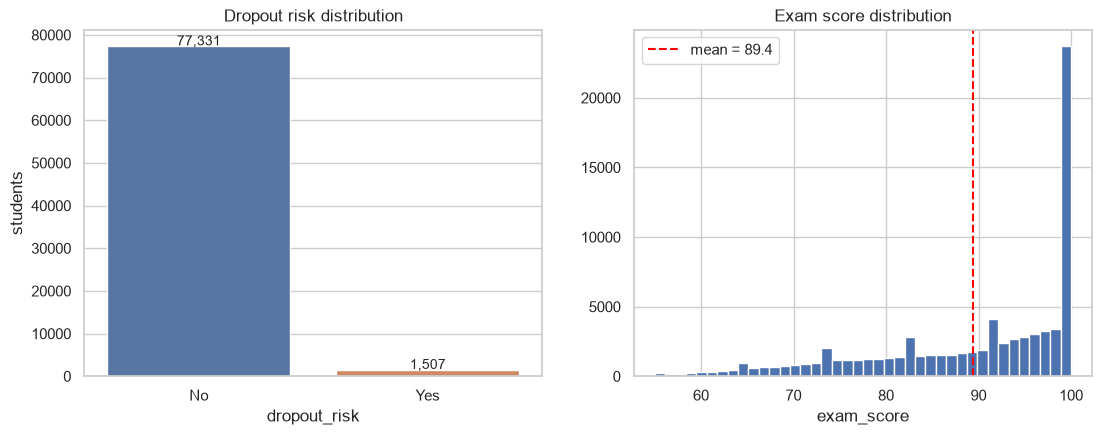

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

counts = clean_df["dropout_risk"].value_counts()
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, legend=False, ax=ax[0])
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 200, f"{v:,}", ha="center", fontsize=10)
ax[0].set_title("Dropout risk distribution")
ax[0].set_xlabel("dropout_risk")
ax[0].set_ylabel("students")

ax[1].hist(clean_df["exam_score"], bins=40, color="#4c72b0", edgecolor="white")
ax[1].axvline(clean_df["exam_score"].mean(), color="red", linestyle="--",
              label=f"mean = {clean_df['exam_score'].mean():.1f}")
ax[1].set_title("Exam score distribution")
ax[1].set_xlabel("exam_score")
ax[1].legend()

fig.savefig(FIGURES_DIR / "eda_targets.png", dpi=150, bbox_inches="tight")
plt.show()

### 5. Correlation heatmap

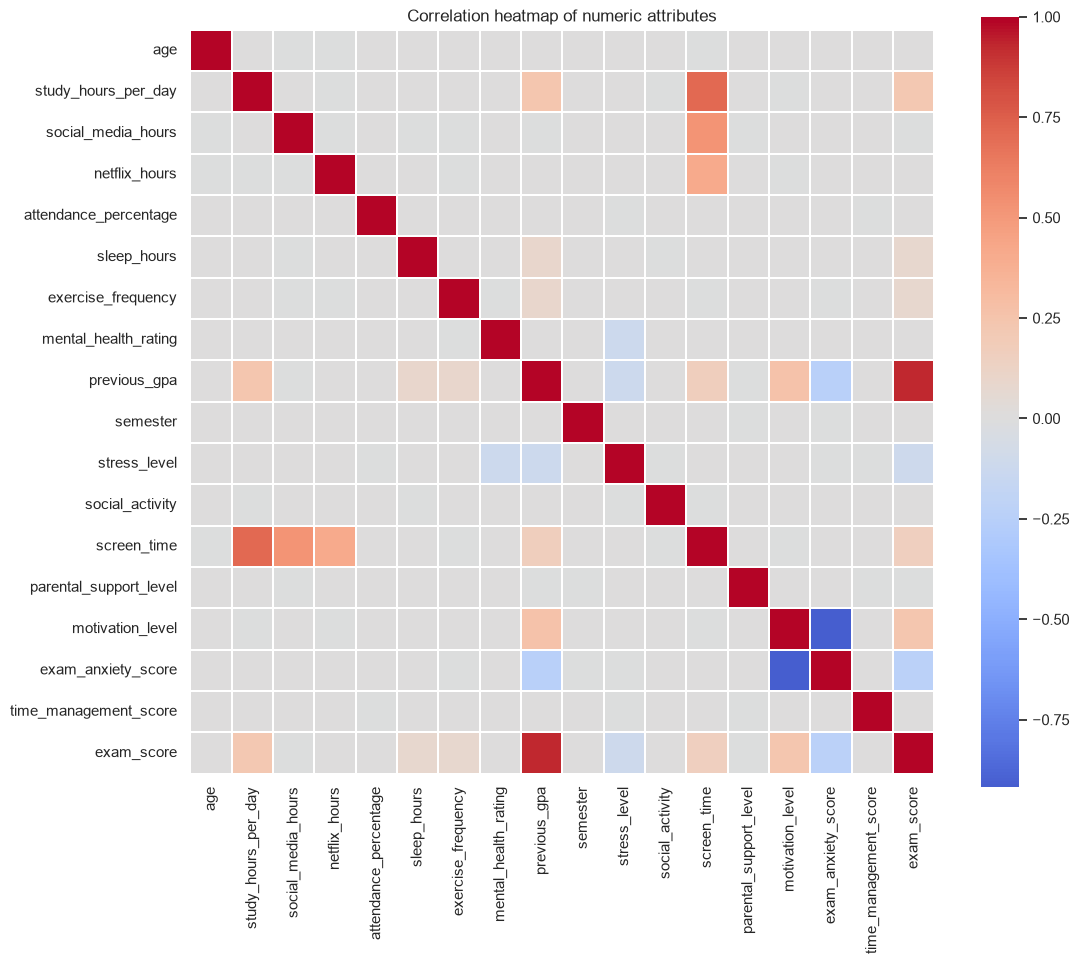

In [7]:
numeric_df = clean_df.select_dtypes(include=[np.number]).drop(columns=["student_id"], errors="ignore")

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(numeric_df.corr(), cmap="coolwarm", center=0, annot=False,
            square=True, linewidths=0.3, ax=ax)
ax.set_title("Correlation heatmap of numeric attributes")

fig.savefig(FIGURES_DIR / "eda_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

### 6. Distribution of key habits

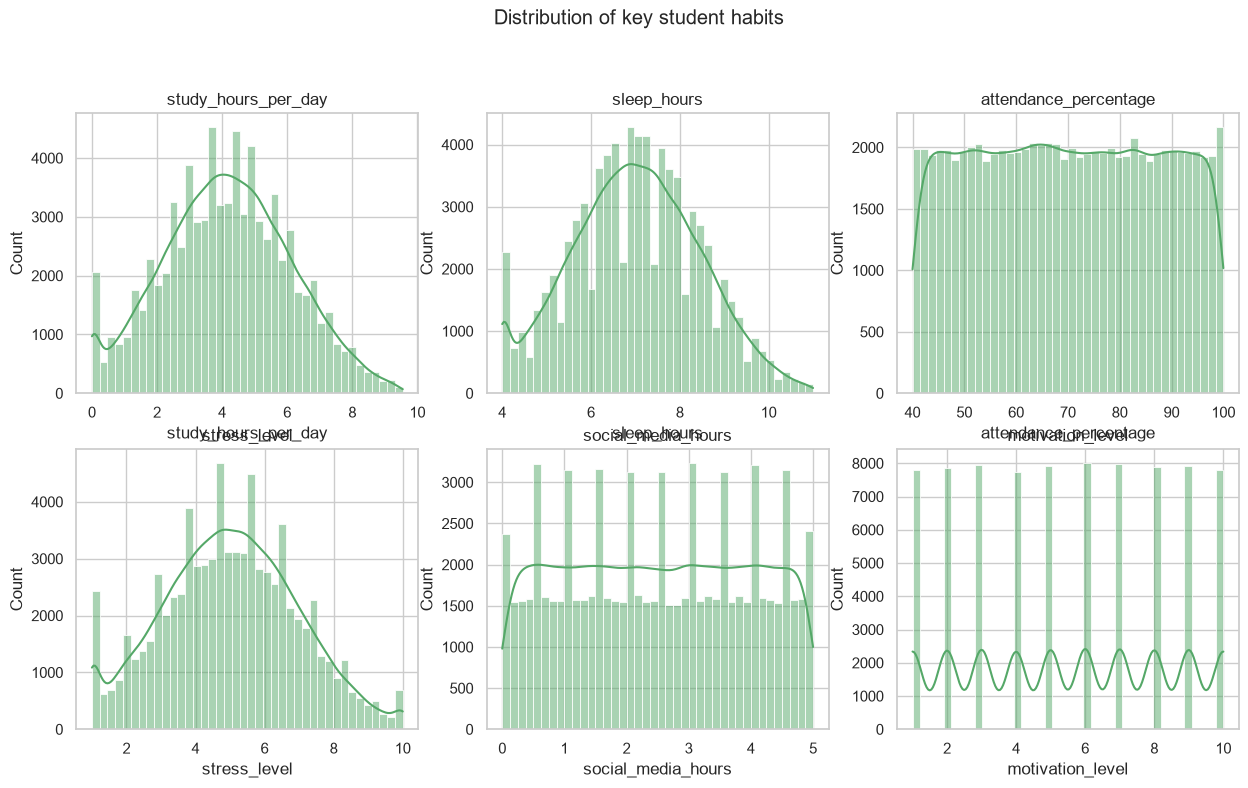

In [8]:
habits = ["study_hours_per_day", "sleep_hours", "attendance_percentage",
          "stress_level", "social_media_hours", "motivation_level"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, habits):
    sns.histplot(clean_df[col], bins=40, kde=True, color="#55a868", ax=ax)
    ax.set_title(col)
fig.suptitle("Distribution of key student habits", y=1.01)

fig.savefig(FIGURES_DIR / "eda_habits.png", dpi=150, bbox_inches="tight")
plt.show()

### 7. What drives academic performance?
Scatter plots of the strongest candidate predictors against the exam score, coloured by dropout risk.

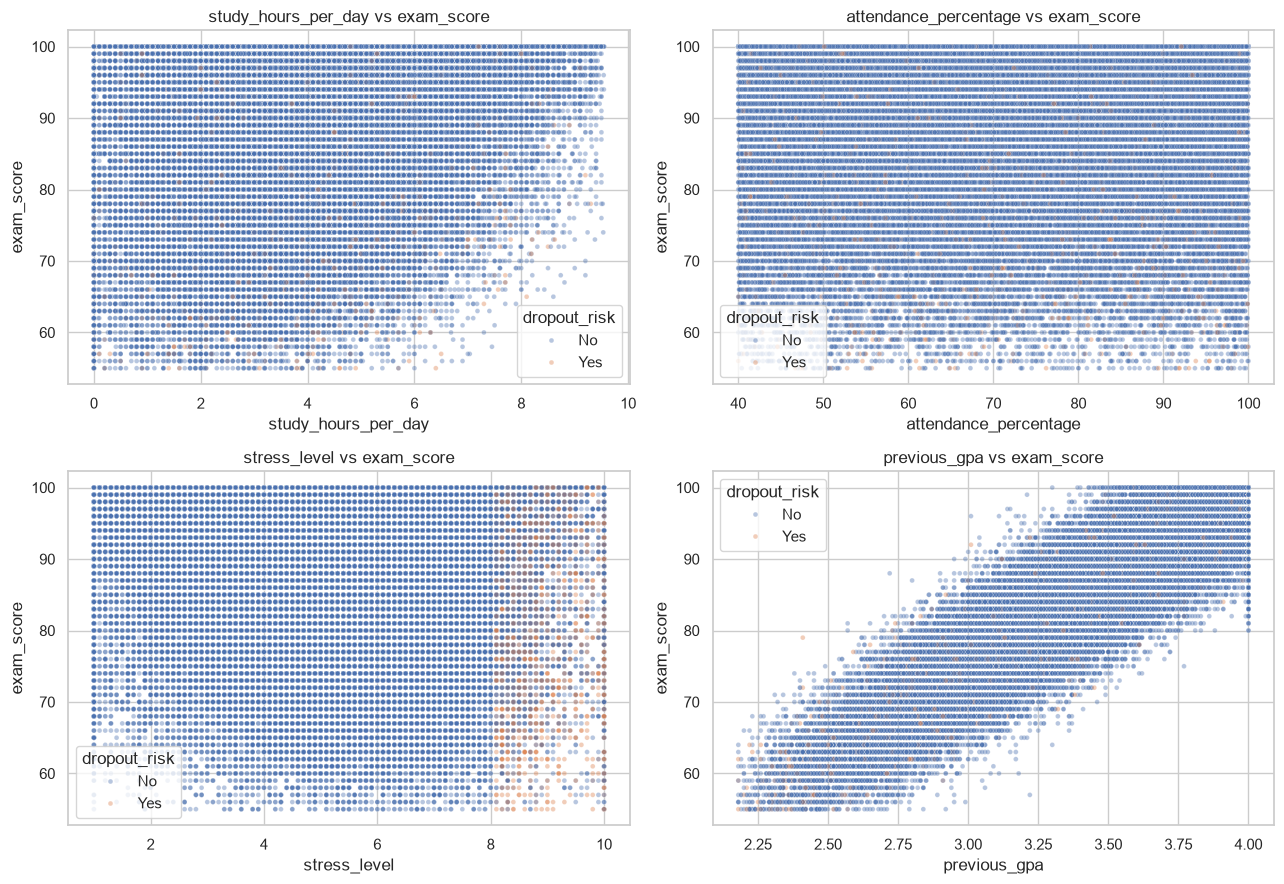

In [9]:
pairs = [("study_hours_per_day", "exam_score"),
         ("attendance_percentage", "exam_score"),
         ("stress_level", "exam_score"),
         ("previous_gpa", "exam_score")]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (x, y) in zip(axes.flat, pairs):
    sns.scatterplot(data=clean_df, x=x, y=y, hue="dropout_risk",
                    s=12, alpha=0.4, ax=ax)
    ax.set_title(f"{x} vs {y}")
fig.tight_layout()

fig.savefig(FIGURES_DIR / "eda_performance_drivers.png", dpi=150, bbox_inches="tight")
plt.show()

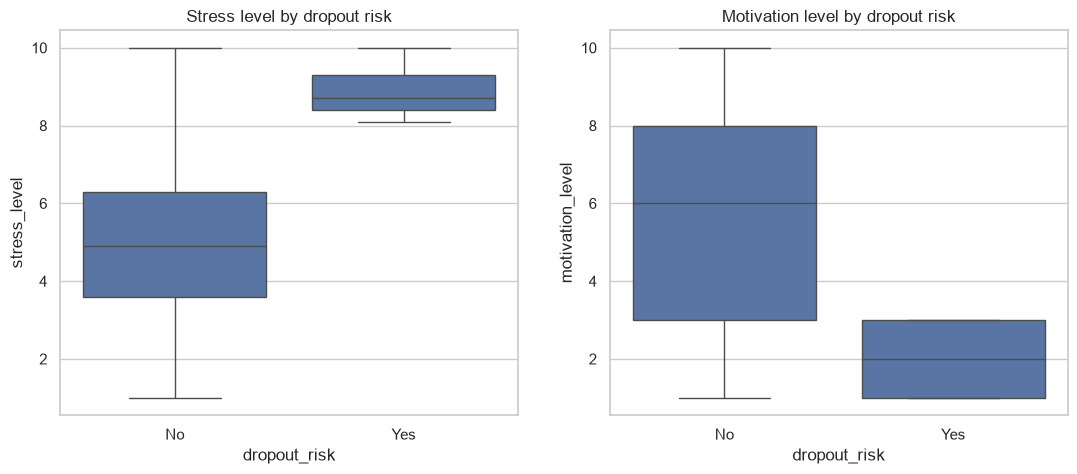

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=clean_df, x="dropout_risk", y="stress_level", ax=ax[0])
ax[0].set_title("Stress level by dropout risk")
sns.boxplot(data=clean_df, x="dropout_risk", y="motivation_level", ax=ax[1])
ax[1].set_title("Motivation level by dropout risk")

fig.savefig(FIGURES_DIR / "eda_stress_vs_risk.png", dpi=150, bbox_inches="tight")
plt.show()

### 8. Key numbers for the report

In [11]:
summary = clean_df.groupby("dropout_risk").agg(
    students=("student_id", "count"),
    avg_exam_score=("exam_score", "mean"),
    avg_stress=("stress_level", "mean"),
    avg_motivation=("motivation_level", "mean"),
    avg_attendance=("attendance_percentage", "mean"),
    avg_study_hours=("study_hours_per_day", "mean"),
).round(2)
print(summary.to_string())

              students  avg_exam_score  avg_stress  avg_motivation  avg_attendance  avg_study_hours
dropout_risk                                                                                       
No               77331           89.47        4.93            5.58           69.99             4.16
Yes               1507           83.22        8.89            1.98           69.08             4.22


### 9. Persist the cleaned dataset

Notebooks 2 and 3 read `data/processed/cleaned.csv`.

In [12]:
clean_df.to_csv("data/processed/cleaned.csv", index=False)
print(f"saved {len(clean_df):,} cleaned rows -> data/processed/cleaned.csv")

saved 78,838 cleaned rows -> data/processed/cleaned.csv
